## XGBoost Forecasting of *Karenia brevis* Conditions: Further Tuning (v2)

This notebook builds on `XGBoostTraining_tuned.ipynb` (v1). v1's main findings were:

1. **Persistence** (repeating the last observed class) beat every XGBoost setup. Its pooled macro-F1 was 0.708 / 0.652 / 0.600 at 1 / 2 / 4 weeks, against 0.634 / 0.557 / 0.488 for tuned XGBoost.
2. **Class-balanced weights** helped at every horizon, while unweighted training was consistently worst.
3. The configuration picked by nested selection **changed from year to year**, and at 4 weeks tuning overfit and scored below the defaults.
4. XGBoost recalled very few **class-1** weeks (2–16%, against 36% for persistence). It mostly misses the weeks when the class changes.

v2 targets each of these weaknesses:

| Step | What it does | Why (from v1) |
| --- | --- | --- |
| **A. Focused search** | Drops the unweighted runs and the two largest feature sets, and samples a new hyperparameter space that adds L1 regularization (`reg_alpha`) and `max_delta_step` | Spends the compute where v1 saw signal |
| **B. Probabilities, not labels** | Stores each model's class probabilities so decisions can be adjusted after training | Needed for C–E |
| **C. Top-5 ensemble** | Averages the 5 best configurations on earlier years instead of picking 1 | v1's single pick was unstable and overfit at 4 weeks |
| **D. Persistence blend** | `p = (1 − α)·p_xgb + α·onehot(last_class)` | Persistence is strong; the model should only override it when confident |
| **E. Class thresholds** | Multiply class probabilities by `(1, w₁, w₂)` before `argmax` | Lifts rare-class recall without retraining |
| **F. Uncertainty** | Bootstrap confidence intervals, resampling whole bloom years, for the gap to persistence | Test years are small and the weeks are autocorrelated |

Every choice in C–E (which configurations, α, w₁, w₂) is made **inside** the nested forward-chaining loop, using earlier bloom years only. The scores reported for 2016–2026 are therefore honest out-of-sample estimates.

**Caveat:** step A (which options to drop) was guided by v1 results on the same 2016–2026 test years. That is a mild form of reusing the test data, so treat small gains with caution. The confidence intervals in step F help here.

### Setup

In [1]:
# !pip install xgboost

In [2]:
import os
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
from sklearn.model_selection import ParameterSampler
from xgboost import XGBClassifier

try:
    from IPython.display import display
except ImportError:  # running as a plain script
    display = print

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

SEED = 42
HORIZONS = [1, 2, 4]
CLASSES = [0, 1, 2]
TEST_YEARS = list(range(2016, 2027))     # reported (outer) folds, same as the first version
CACHE_YEARS = list(range(2013, 2027))    # 2013-2015 are used only for inner model selection
N_HP_CONFIGS = 12                        # new random draws (plus defaults and v1's best 1-week set)
N_JOBS = -1                              # parallel fits; lower this if memory is tight

### Load the Weekly Dataset

In Colab this mounts Google Drive. Run locally, it reads `merged_weekly_sarasota.csv` from the working directory.

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/data"
    os.chdir(DATA_DIR)
    DATA_PATH = "merged/merged_weekly_sarasota.csv"
except ImportError:
    DATA_PATH = "merged/merged_weekly_sarasota.csv"
    if not os.path.exists(DATA_PATH):
        DATA_PATH = "merged_weekly_sarasota.csv"

RESULTS_DIR = "results_v2"
os.makedirs(RESULTS_DIR, exist_ok=True)

dataset = pd.read_csv(DATA_PATH, parse_dates=["week_ending"])
dataset = dataset.sort_values("week_ending").reset_index(drop=True)

TARGETS = [f"target_{h}w" for h in HORIZONS]
print(dataset.shape, dataset["week_ending"].min().date(), "to", dataset["week_ending"].max().date())

# The lag features below rely on one row per week with no gaps
gaps = dataset["week_ending"].diff().dropna().dt.days
assert (gaps == 7).all(), "Weekly series has gaps; lag features would be misaligned"

(853, 89) 2010-01-03 to 2026-05-03


### Data Checks

Count each class per bloom year and check for missing values. Columns that are entirely empty carry no information and are dropped.

In [4]:
bloom_year = dataset["week_ending"].dt.year + (dataset["week_ending"].dt.month >= 8)
print("target_1w class counts by bloom year (Aug-Jul):")
display(pd.crosstab(bloom_year, dataset["target_1w"]).rename_axis(index="bloom_year"))

missing = dataset.isna().mean().sort_values(ascending=False)
print("Most-missing columns (fraction missing):")
display(missing.head(12).round(3).to_frame("frac_missing"))

all_missing = missing[missing == 1.0].index.tolist()
print("Dropping fully-missing columns:", all_missing)
dataset = dataset.drop(columns=all_missing)

target_1w class counts by bloom year (Aug-Jul):


target_1w,0.0,1.0,2.0
bloom_year,,,
2010,30,0,0
2011,53,0,0
2012,49,1,2
2013,23,7,22
2014,48,2,2
2015,52,0,0
2016,22,12,19
2017,18,6,28
2018,29,9,14


Most-missing columns (fraction missing):


,frac_missing
bay_tss_8w,1.000
creek_chl_uncorr_8w,0.816
mote_water_temp_c,0.776
wind_u_4w,0.768
wind_v_4w,0.768
wind_u,0.767
wind_v,0.767
pressure_mb,0.767
wind_speed,0.767
ksrq_air_temp_c,0.767


Dropping fully-missing columns: ['bay_tss_8w']


### Lagged Environmental Variables

The merged data already contains *K. brevis* lags and 8-week nutrient windows. What it lacks is **lagged physical and environmental drivers**: conditions 2, 4 and 8 weeks before the forecast origin, plus 4-week changes. Blooms can respond to upwelling winds, temperature, runoff and nutrients with a delay, so these lags may add lead time.

The lags use `shift(k)` on the gap-free weekly series, so each row sees only past values and nothing leaks from the future.

In [5]:
LAG_VARS = [
    "water_temp_c", "chl_mean_log", "chl_anomaly", "chl_coastal_anomaly", "chl_p90",
    "habsos_salinity", "rain_in_4w", "wind_v_4w", "wind_u_4w", "grid_uwnd_4w",
    "air_temp_f", "bay_po4_8w", "bay_tn_8w", "creek_nox_8w", "creek_po4_8w",
]
LAGS = [2, 4, 8]

lag_frames = {}
for var in LAG_VARS:
    for k in LAGS:
        lag_frames[f"{var}_lag{k}"] = dataset[var].shift(k)
    lag_frames[f"{var}_chg4w"] = dataset[var] - dataset[var].shift(4)

lag_df = pd.DataFrame(lag_frames)
ENV_LAG_COLS = lag_df.columns.tolist()
dataset = pd.concat([dataset, lag_df], axis=1)
print(f"Added {len(ENV_LAG_COLS)} lagged environmental features")

Added 60 lagged environmental features


### Feature Subsets

Columns are grouped by data source, and six subsets are compared. Every subset includes the *K. brevis* history, since it is by far the strongest signal.

In [6]:
original_cols = [c for c in dataset.columns
                 if c not in ["week_ending"] + TARGETS + ENV_LAG_COLS]

KB_COLS = [c for c in original_cols
           if c.startswith(("kb_", "rkb_"))
           or c in ["last_class", "weeks_since_sample", "weeks_since_bloom"]]
SEASON_COLS = ["woy_sin", "woy_cos"]
CHL_COLS = [c for c in original_cols if c.startswith("chl_")]
NUTRIENT_COLS = [c for c in original_cols if c.startswith(("bay_", "creek_"))]
PHYSICAL_COLS = [c for c in original_cols
                 if c not in KB_COLS + SEASON_COLS + CHL_COLS + NUTRIENT_COLS]

FEATURE_SETS = {
    "kb_only":          KB_COLS + SEASON_COLS,
    "kb_physical":      KB_COLS + SEASON_COLS + PHYSICAL_COLS + CHL_COLS,
    "kb_physical_lags": KB_COLS + SEASON_COLS + PHYSICAL_COLS + CHL_COLS + ENV_LAG_COLS,
    "kb_nutrients":     KB_COLS + SEASON_COLS + NUTRIENT_COLS,
    "all":              original_cols,
    "all_lags":         original_cols + ENV_LAG_COLS,
}

# Sanity check: every original column is in exactly one group
assert sorted(KB_COLS + SEASON_COLS + CHL_COLS + NUTRIENT_COLS + PHYSICAL_COLS) == sorted(original_cols)

display(pd.DataFrame({"n_features": {k: len(v) for k, v in FEATURE_SETS.items()}}))
print("Physical columns:", PHYSICAL_COLS)

,n_features
kb_only,25
kb_physical,54
kb_physical_lags,114
kb_nutrients,55
all,84
all_lags,144


Physical columns: ['mote_water_temp_c', 'habsos_water_temp_c', 'habsos_salinity', 'water_temp_c', 'water_temp_change_2w', 'warm_weeks_8w', 'air_temp_f', 'air_temp_max_f', 'rain_in_1w', 'rain_in_4w', 'rain_in_8w', 'rain_in_12w', 'wind_u', 'wind_v', 'wind_speed', 'wind_v_4w', 'wind_u_4w', 'ksrq_air_temp_c', 'pressure_mb', 'grid_uwnd', 'grid_uwnd_4w']


### Forward-Chaining Folds and Metrics

Folds are the same as in the first version. Bloom year *Y* covers forecast-origin weeks from Aug 1 of *Y−1* up to Aug 1 of *Y*. The model trains only on rows whose **target date** falls before the test period starts, so no label from the test period can enter training.

Metrics:
* **Pooled macro-F1** (primary): F1 averaged over classes 0, 1 and 2, computed on every out-of-fold prediction for the horizon at once.
* **Mean per-year macro-F1** and **accuracy**: the first version's metrics, kept for comparison.
* **Recall and F1 for classes 1 and 2**: how well blooms are actually detected.

In [7]:
def horizon_data(horizon):
    """Rows with a known target for this horizon, plus the date the target refers to."""
    target = f"target_{horizon}w"
    data = dataset.dropna(subset=[target]).copy()
    data[target] = data[target].astype(int)
    data["target_week"] = data["week_ending"] + pd.to_timedelta(7 * horizon, unit="D")
    return data, target


def make_folds(data, target, years):
    """Forward-chaining folds by Aug-Jul bloom year."""
    folds = []
    for year in years:
        test_start = pd.Timestamp(year=year - 1, month=8, day=1)
        test_end = pd.Timestamp(year=year, month=8, day=1)
        test_idx = data.index[(data["week_ending"] >= test_start) & (data["week_ending"] < test_end)]
        train_idx = data.index[data["target_week"] < test_start]
        if len(test_idx) == 0:
            continue
        # XGBoost needs every class present in training to keep labels 0..2 aligned
        if set(data.loc[train_idx, target].unique()) != set(CLASSES):
            continue
        folds.append((year, train_idx, test_idx))
    return folds


def score(y_true, y_pred):
    """Pooled metrics over a fixed label set so rare classes always count."""
    f1s = f1_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    recalls = recall_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    return {
        "macro_f1": f1s.mean(),
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_c1": f1s[1], "f1_c2": f1s[2],
        "recall_c1": recalls[1], "recall_c2": recalls[2],
    }


def mean_fold_macro_f1(df):
    """The first version's metric: macro-F1 per test year, then averaged."""
    return df.groupby("test_year").apply(
        lambda g: f1_score(g["y_true"], g["y_pred"], average="macro", zero_division=0),
        include_groups=False,
    ).mean()


def summarize(pred_df):
    """Pooled metrics over the reported test years plus the per-year mean."""
    p = pred_df[pred_df["test_year"].isin(TEST_YEARS)]
    out = score(p["y_true"], p["y_pred"])
    out["mean_year_macro_f1"] = mean_fold_macro_f1(p)
    out["n"] = len(p)
    return out

### Class Weighting

* `none`: every week counts equally (the first version).
* `balanced`: each class gets total weight inversely proportional to its frequency, as in sklearn's `"balanced"` option.
* `sqrt`: the square root of the balanced weights. This is a milder correction that often keeps precision on the majority class while still lifting rare-class recall.

In [8]:
def sample_weights(y, scheme):
    if scheme == "none":
        return None
    counts = y.value_counts()
    w = len(y) / (len(counts) * counts)
    if scheme == "sqrt":
        w = np.sqrt(w)
    weights = y.map(w).to_numpy(dtype=float)
    return weights / weights.mean()

### Shared Helpers

`macro_f1_np` gives the same result as sklearn's `f1_score(labels=[0, 1, 2], average="macro", zero_division=0)`, but runs much faster. That matters because the nested loop scores thousands of candidate settings.

In [9]:
BASE_PARAMS = dict(
    objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
    random_state=SEED, n_jobs=1,
)
K_ENSEMBLE = 5
ONE_HOT = np.eye(len(CLASSES))


def macro_f1_np(y, pred):
    cm = np.bincount(np.asarray(y) * 3 + np.asarray(pred), minlength=9).reshape(3, 3)
    tp = np.diag(cm)
    denom = 2 * tp + (cm.sum(0) - tp) + (cm.sum(1) - tp)
    return np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0).mean()


# Quick check that it matches sklearn
_rng = np.random.default_rng(0)
_y, _p = _rng.integers(0, 3, 200), _rng.integers(0, 3, 200)
assert np.isclose(macro_f1_np(_y, _p),
                  f1_score(_y, _p, labels=CLASSES, average="macro", zero_division=0))


def fit_proba(params, feats, weighting, data, target, train_idx, test_idx):
    X_train = data.loc[train_idx, feats]
    y_train = data.loc[train_idx, target]
    model = XGBClassifier(**BASE_PARAMS, **params)
    model.fit(X_train, y_train, sample_weight=sample_weights(y_train, weighting))
    return model, model.predict_proba(data.loc[test_idx, feats])


def fold_frame(data, target, year, test_idx, proba, **meta):
    proba = np.asarray(proba, dtype=float)
    return pd.DataFrame({
        "test_year": year,
        "row": test_idx,
        "target_week": data.loc[test_idx, "target_week"].to_numpy(),
        "y_true": data.loc[test_idx, target].to_numpy(),
        "last_class": data.loc[test_idx, "last_class"].astype(int).to_numpy(),
        "p0": proba[:, 0], "p1": proba[:, 1], "p2": proba[:, 2],
        **meta,
    })


def with_pred(df):
    df = df.copy()
    df["y_pred"] = df[["p0", "p1", "p2"]].to_numpy().argmax(1)
    return df

### Reference Results

These are persistence and v1's default XGBoost (all features, no weighting), scored on the same test weeks as everything below. The v1 tuned results are listed in the comparison table at the end.

In [10]:
ref_cache = os.path.join(RESULTS_DIR, "reference_preds.csv.gz")
if os.path.exists(ref_cache):
    reference_preds = pd.read_csv(ref_cache, parse_dates=["target_week"])
    print("Loaded cached reference predictions")
else:
    reference_preds = []
    for horizon in HORIZONS:
        data, target = horizon_data(horizon)
        for year, train_idx, test_idx in make_folds(data, target, TEST_YEARS):
            persistence = ONE_HOT[data.loc[test_idx, "last_class"].astype(int)]
            reference_preds.append(fold_frame(data, target, year, test_idx, persistence,
                                              horizon=horizon, model="Persistence (last_class)"))
            _, proba = fit_proba({}, original_cols, "none", data, target, train_idx, test_idx)
            reference_preds.append(fold_frame(data, target, year, test_idx, proba,
                                              horizon=horizon, model="Default XGBoost (v1 baseline)"))
    reference_preds = pd.concat(reference_preds, ignore_index=True)
    reference_preds.to_csv(ref_cache, index=False)

reference_preds = with_pred(reference_preds)
reference_summary = pd.DataFrame([
    {"horizon": h, "model": m, **summarize(g)}
    for (h, m), g in reference_preds.groupby(["horizon", "model"])
])
display(reference_summary.round(3))

Loaded cached reference predictions


,horizon,model,macro_f1,accuracy,f1_c1,f1_c2,recall_c1,recall_c2,mean_year_macro_f1,n
0,1,Default XGBoost (v1 baseline),0.607,0.826,0.098,0.820,0.06,0.847,0.559,448
1,1,Persistence (last_class),0.708,0.833,0.360,0.856,0.36,0.856,0.722,448
2,2,Default XGBoost (v1 baseline),0.544,0.770,0.065,0.703,0.04,0.653,0.551,447
3,2,Persistence (last_class),0.652,0.790,0.280,0.797,0.28,0.797,0.670,447
4,4,Default XGBoost (v1 baseline),0.509,0.735,0.033,0.670,0.02,0.593,0.517,445
5,4,Persistence (last_class),0.600,0.744,0.238,0.712,0.24,0.703,0.599,445


### A. Focused Search Space

* **Feature subsets:** the four compact subsets (`kb_only`, `kb_physical`, `kb_physical_lags`, `kb_nutrients`). The two largest (`all`, `all_lags`) never led on median score in v1 and are the slowest to train.
* **Weighting:** `balanced` only. In v1 it had the highest median macro-F1 at every horizon, and step E now handles finer rare-class adjustment after training.
* **Hyperparameters:** XGBoost defaults, v1's best 1-week setting, and 12 new random draws. The new space is shallow (depth 2–4, at most 300 trees) and adds `reg_alpha` (L1) and `max_delta_step`. XGBoost's documentation recommends `max_delta_step` for imbalanced classes because it caps each tree's update.

In [11]:
V2_FEATURE_SETS = ["kb_only", "kb_physical", "kb_physical_lags", "kb_nutrients"]
V2_WEIGHTING = "balanced"

param_space = {
    "n_estimators": [100, 150, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_child_weight": [1, 2, 3, 5],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.5, 0.7, 0.9],
    "reg_lambda": [1, 3, 10],
    "reg_alpha": [0, 0.5, 1.0],
    "gamma": [0, 0.25, 0.5],
    "max_delta_step": [0, 1, 2],
}
V1_BEST_1W = {"subsample": 0.85, "reg_lambda": 1, "n_estimators": 100, "min_child_weight": 1,
              "max_depth": 4, "learning_rate": 0.1, "gamma": 0.5, "colsample_bytree": 0.6}
HP_CONFIGS = [{}, V1_BEST_1W] + list(ParameterSampler(param_space, n_iter=N_HP_CONFIGS,
                                                      random_state=SEED))

CONFIGS = [{"config_id": f"{fs}|hp{i}", "feature_set": fs, "weighting": V2_WEIGHTING,
            "hp_id": i, "params": p}
           for fs in V2_FEATURE_SETS for i, p in enumerate(HP_CONFIGS)]
cfg_meta = pd.DataFrame(CONFIGS).drop(columns="params").set_index("config_id")

hp_table = pd.DataFrame(HP_CONFIGS).rename_axis("hp_id").astype(object)
hp_table.index = ["defaults", "v1 best 1w"] + [f"hp{i}" for i in range(2, len(HP_CONFIGS))]
display(hp_table.fillna("-"))
print(f"{len(CONFIGS)} configurations per horizon")

,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,reg_alpha,max_delta_step
defaults,-,-,-,-,-,-,-,-,-,-
v1 best 1w,0.85,1.0,100.0,1.0,4.0,0.1,0.5,0.6,-,-
hp2,0.7,1.0,150.0,3.0,2.0,0.05,0.25,0.5,0.0,0.0
hp3,0.9,3.0,300.0,5.0,3.0,0.03,0.0,0.5,1.0,0.0
hp4,0.9,3.0,100.0,1.0,2.0,0.1,0.5,0.9,0.5,2.0
hp5,0.9,3.0,150.0,5.0,2.0,0.05,0.0,0.9,0.0,2.0
hp6,0.8,3.0,100.0,1.0,3.0,0.1,0.25,0.7,1.0,0.0
hp7,0.8,1.0,100.0,3.0,4.0,0.05,0.0,0.5,0.0,1.0
hp8,0.7,1.0,300.0,3.0,3.0,0.03,0.25,0.9,0.5,0.0
hp9,0.7,10.0,150.0,1.0,4.0,0.03,0.0,0.7,0.5,1.0


56 configurations per horizon


### B. Run the Search, Storing Class Probabilities

Every configuration is trained on every fold from 2013 to 2026 and every horizon, using the same forward-chaining folds as v1. Each horizon is cached separately in `results_v2/`, so an interrupted run resumes where it stopped.

In [12]:
def run_config_fold(cfg, horizon, data, target, year, train_idx, test_idx):
    _, proba = fit_proba(cfg["params"], FEATURE_SETS[cfg["feature_set"]], cfg["weighting"],
                         data, target, train_idx, test_idx)
    return fold_frame(data, target, year, test_idx, proba,
                      horizon=horizon, config_id=cfg["config_id"])


cache_key = hashlib.md5(json.dumps(
    [CONFIGS, CACHE_YEARS, {k: FEATURE_SETS[k] for k in V2_FEATURE_SETS}, SEED, len(dataset)],
    sort_keys=True, default=str).encode()).hexdigest()[:10]

search_parts = []
for horizon in HORIZONS:
    path = os.path.join(RESULTS_DIR, f"search_probs_{horizon}w_{cache_key}.csv.gz")
    if os.path.exists(path):
        part = pd.read_csv(path, parse_dates=["target_week"])
        print(f"{horizon}-week: loaded cached search ({path})")
    else:
        data, target = horizon_data(horizon)
        jobs = [delayed(run_config_fold)(cfg, horizon, data, target, year, tr, te)
                for year, tr, te in make_folds(data, target, CACHE_YEARS) for cfg in CONFIGS]
        print(f"{horizon}-week: training {len(jobs)} models ...", flush=True)
        part = pd.concat(Parallel(n_jobs=N_JOBS)(jobs), ignore_index=True)
        part.to_csv(path, index=False)
        print(f"{horizon}-week: saved {path}", flush=True)
    search_parts.append(part)

search_preds = with_pred(pd.concat(search_parts, ignore_index=True))

1-week: loaded cached search (results_v2\search_probs_1w_cf32380bcf.csv.gz)
2-week: loaded cached search (results_v2\search_probs_2w_cf32380bcf.csv.gz)


4-week: loaded cached search (results_v2\search_probs_4w_cf32380bcf.csv.gz)


### Search Overview

Each configuration scored by plain `argmax` on the 2016–2026 folds. As in v1, the top row is an **optimistic** (hindsight) number; the honest numbers come from the nested procedure below.

In [13]:
leaderboard = pd.DataFrame([
    {"horizon": h, "config_id": cid, **summarize(g)}
    for (h, cid), g in search_preds.groupby(["horizon", "config_id"])
]).join(cfg_meta, on="config_id")

for horizon in HORIZONS:
    lb = leaderboard[leaderboard["horizon"] == horizon]
    print(f"\n{horizon}-week: top 5 configurations (hindsight)")
    display(lb.nlargest(5, "macro_f1")[["config_id", "macro_f1", "accuracy", "recall_c1",
                                        "recall_c2"]].round(3).reset_index(drop=True))

print("\nMedian pooled macro-F1 over hyperparameter sets, by feature subset:")
display(leaderboard.pivot_table(index="feature_set", columns="horizon", values="macro_f1",
                                aggfunc="median").round(3))


1-week: top 5 configurations (hindsight)


,config_id,macro_f1,accuracy,recall_c1,recall_c2
0,kb_only|hp1,0.676,0.808,0.32,0.805
1,kb_only|hp4,0.652,0.788,0.30,0.805
2,kb_only|hp11,0.650,0.797,0.26,0.805
3,kb_only|hp13,0.646,0.797,0.24,0.831
4,kb_nutrients|hp7,0.646,0.826,0.16,0.847



2-week: top 5 configurations (hindsight)


,config_id,macro_f1,accuracy,recall_c1,recall_c2
0,kb_physical_lags|hp5,0.610,0.772,0.18,0.814
1,kb_physical_lags|hp3,0.607,0.783,0.14,0.822
2,kb_physical_lags|hp12,0.606,0.774,0.16,0.831
3,kb_physical_lags|hp0,0.606,0.801,0.10,0.822
4,kb_physical_lags|hp2,0.606,0.770,0.16,0.822



4-week: top 5 configurations (hindsight)


,config_id,macro_f1,accuracy,recall_c1,recall_c2
0,kb_nutrients|hp1,0.588,0.773,0.12,0.686
1,kb_nutrients|hp0,0.585,0.769,0.12,0.669
2,kb_only|hp2,0.579,0.735,0.16,0.763
3,kb_nutrients|hp8,0.578,0.762,0.12,0.661
4,kb_nutrients|hp11,0.578,0.762,0.12,0.653



Median pooled macro-F1 over hyperparameter sets, by feature subset:


horizon,1,2,4
feature_set,,,
kb_nutrients,0.626,0.568,0.568
kb_only,0.637,0.569,0.535
kb_physical,0.621,0.581,0.525
kb_physical_lags,0.605,0.599,0.531


### C–E. Nested Pipeline: Ensemble, Persistence Blend and Class Thresholds

For each horizon and test year *Y*, using **earlier** years only (validation weeks whose target date falls inside *Y* are dropped):

1. **Rank** all configurations by pooled macro-F1 on the earlier years.
2. **Ensemble (C):** average the class probabilities of the top `K_ENSEMBLE = 5`.
3. **Blend (D):** mix in persistence with weight α ∈ {0, 0.2, 0.35, 0.5}. At α = 0.5 with no threshold change, the forecast is exactly persistence, so the pipeline can fall back to it whenever the earlier years say it should.
4. **Thresholds (E):** scale class 1 by w₁ ∈ {1, 1.5, 2, 3, 4} and class 2 by w₂ ∈ {0.75, 1, 1.5}, then take the `argmax`.
5. Choose (α, w₁, w₂) on the same earlier years. To limit overfitting on small data, **the simplest setting within 0.005 of the best score wins**, with simpler meaning closer to α = 0 and w = 1.

Four simpler variants are scored the same way, to show what each step adds.

In [14]:
ALPHAS = [0.0, 0.2, 0.35, 0.5]
W1S = [1.0, 1.5, 2.0, 3.0, 4.0]
W2S = [1.0, 0.75, 1.5]
TOL = 0.005


def horizon_arrays(preds_h):
    """Reshape one horizon's predictions into arrays: probabilities P[config, row, class]."""
    config_ids = [c for c in cfg_meta.index if c in set(preds_h["config_id"])]
    first = preds_h[preds_h["config_id"] == config_ids[0]].sort_values("row")
    rows = first["row"].to_numpy()
    P = np.stack([
        preds_h[preds_h["config_id"] == c].set_index("row").loc[rows, ["p0", "p1", "p2"]].to_numpy()
        for c in config_ids
    ])
    return {
        "config_ids": config_ids, "P": P, "rows": rows,
        "year": first["test_year"].to_numpy(), "tw": first["target_week"].to_numpy(),
        "y": first["y_true"].to_numpy(), "last": first["last_class"].to_numpy(),
        "target_week": first["target_week"].to_numpy(),
    }


def post_grid(alphas, w1s, w2s):
    """Candidate (alpha, w1, w2), simplest first."""
    grid = [(a, w1, w2) for a in alphas for w1 in w1s for w2 in w2s]
    return sorted(grid, key=lambda g: (g[0], abs(g[1] - 1), abs(g[2] - 1)))


def apply_post(P, last, alpha, w1, w2):
    Q = (1 - alpha) * P + alpha * ONE_HOT[last]
    return (Q * np.array([1.0, w1, w2])).argmax(1)


def choose_post(P, y, last, grid):
    scores = np.array([macro_f1_np(y, apply_post(P, last, *g)) for g in grid])
    ok = np.flatnonzero(scores >= scores.max() - TOL)
    return grid[ok[0]], scores[ok[0]]


VARIANTS = {
    "v2: single best config":             dict(k=1, grid=[(0.0, 1.0, 1.0)]),
    "v2: top-5 ensemble":                 dict(k=K_ENSEMBLE, grid=[(0.0, 1.0, 1.0)]),
    "v2: ensemble + persistence blend":   dict(k=K_ENSEMBLE, grid=post_grid(ALPHAS, [1.0], [1.0])),
    "v2: ensemble + class thresholds":    dict(k=K_ENSEMBLE, grid=post_grid([0.0], W1S, W2S)),
    "v2: ensemble + blend + thresholds":  dict(k=K_ENSEMBLE, grid=post_grid(ALPHAS, W1S, W2S)),
}


def run_pipeline(A, inner_mask, k, grid):
    """Select configs and post-processing on inner_mask; return ensemble probs and settings."""
    scores = np.array([macro_f1_np(A["y"][inner_mask], A["P"][c, inner_mask].argmax(1))
                       for c in range(len(A["config_ids"]))])
    top = np.argsort(-scores, kind="stable")[:k]
    P_ens = A["P"][top].mean(0)
    (alpha, w1, w2), inner_score = choose_post(P_ens[inner_mask], A["y"][inner_mask],
                                               A["last"][inner_mask], grid)
    return P_ens, top, (alpha, w1, w2), inner_score


nested_rows, choices = [], []
arrays = {}
for horizon in HORIZONS:
    A = horizon_arrays(search_preds[search_preds["horizon"] == horizon])
    arrays[horizon] = A
    for year in TEST_YEARS:
        test_start = pd.Timestamp(year=year - 1, month=8, day=1)
        inner = (A["year"] < year) & (A["tw"] < np.datetime64(test_start))
        outer = A["year"] == year
        if not outer.any():
            continue
        for name, v in VARIANTS.items():
            P_ens, top, (alpha, w1, w2), inner_score = run_pipeline(A, inner, v["k"], v["grid"])
            pred = apply_post(P_ens[outer], A["last"][outer], alpha, w1, w2)
            nested_rows.append(pd.DataFrame({
                "horizon": horizon, "model": name, "test_year": year, "row": A["rows"][outer],
                "y_true": A["y"][outer], "y_pred": pred,
            }))
            if name == "v2: ensemble + blend + thresholds":
                choices.append({"horizon": horizon, "test_year": year,
                                "top_config": A["config_ids"][top[0]],
                                "alpha": alpha, "w1": w1, "w2": w2,
                                "inner_macro_f1": round(inner_score, 3)})

nested_preds = pd.concat(nested_rows, ignore_index=True)
choices = pd.DataFrame(choices)
print("Settings chosen for each test year by the full pipeline (earlier years only):")
display(choices.pivot(index="test_year", columns="horizon",
                      values=["alpha", "w1", "w2"]).round(2))

Settings chosen for each test year by the full pipeline (earlier years only):


alpha              w1             w2          
horizon       1     2    4    1    2    4    1    2    4
test_year                                               
2016        0.5  0.50  0.5  1.0  2.0  4.0  1.0  1.0  1.0
2017        0.5  0.50  0.5  1.5  2.0  1.0  1.0  1.0  1.5
2018        0.5  0.50  0.5  1.5  2.0  1.0  1.0  1.0  1.5
2019        0.5  0.35  0.5  1.5  2.0  1.0  1.0  1.5  1.0
2020        0.5  0.35  0.5  1.5  2.0  2.0  1.0  1.5  1.0
2021        0.5  0.50  0.5  1.5  3.0  2.0  1.0  1.0  1.0
2022        0.5  0.35  0.5  2.0  2.0  1.0  1.5  1.5  1.0
2023        0.5  0.35  0.5  2.0  2.0  1.0  1.5  1.5  1.0
2024        0.5  0.50  0.5  1.5  1.0  1.0  1.5  1.0  1.0
2025        0.5  0.50  0.5  1.5  1.0  2.0  1.0  1.0  1.0
2026        0.5  0.50  0.5  1.5  1.5  1.5  1.0  1.0  1.0

### Results: What Each Step Adds

Every row is an honest out-of-sample score on the 2016–2026 test weeks. v1's tuned results are added from the v1 notebook for comparison.

In [15]:
all_preds = pd.concat([reference_preds[["horizon", "model", "test_year", "row", "y_true", "y_pred"]],
                       nested_preds], ignore_index=True)

MODEL_ORDER = ["Persistence (last_class)", "Default XGBoost (v1 baseline)"] + list(VARIANTS)
results = pd.DataFrame([
    {"horizon": h, "model": m, **summarize(all_preds[(all_preds["horizon"] == h) &
                                                     (all_preds["model"] == m)])}
    for h in HORIZONS for m in MODEL_ORDER
])

V1_TUNED = {1: (0.634, 0.810, 0.16), 2: (0.557, 0.720, 0.12), 4: (0.488, 0.692, 0.02)}
v1_rows = pd.DataFrame([{"horizon": h, "model": "v1: tuned XGBoost (nested)", "macro_f1": v[0],
                         "accuracy": v[1], "recall_c1": v[2]} for h, v in V1_TUNED.items()])
results = pd.concat([results, v1_rows], ignore_index=True)
MODEL_ORDER.insert(2, "v1: tuned XGBoost (nested)")
results["model"] = pd.Categorical(results["model"], MODEL_ORDER, ordered=True)
results = results.sort_values(["horizon", "model"])

cols = ["horizon", "model", "macro_f1", "accuracy", "recall_c1", "f1_c1", "recall_c2",
        "mean_year_macro_f1"]
display(results[cols].round(3).reset_index(drop=True))

,horizon,model,macro_f1,accuracy,recall_c1,f1_c1,recall_c2,mean_year_macro_f1
0,1,Persistence (last_class),0.708,0.833,0.36,0.360,0.856,0.722
1,1,Default XGBoost (v1 baseline),0.607,0.826,0.06,0.098,0.847,0.559
2,1,v1: tuned XGBoost (nested),0.634,0.810,0.16,NaN,NaN,NaN
3,1,v2: single best config,0.626,0.790,0.18,0.196,0.839,0.552
4,1,v2: top-5 ensemble,0.626,0.801,0.16,0.184,0.839,0.556
5,1,v2: ensemble + persistence blend,0.708,0.833,0.36,0.360,0.856,0.722
6,1,v2: ensemble + class thresholds,0.626,0.786,0.20,0.211,0.822,0.555
7,1,v2: ensemble + blend + thresholds,0.709,0.830,0.38,0.373,0.856,0.648
8,2,Persistence (last_class),0.652,0.790,0.28,0.280,0.797,0.670
9,2,Default XGBoost (v1 baseline),0.544,0.770,0.04,0.065,0.653,0.551


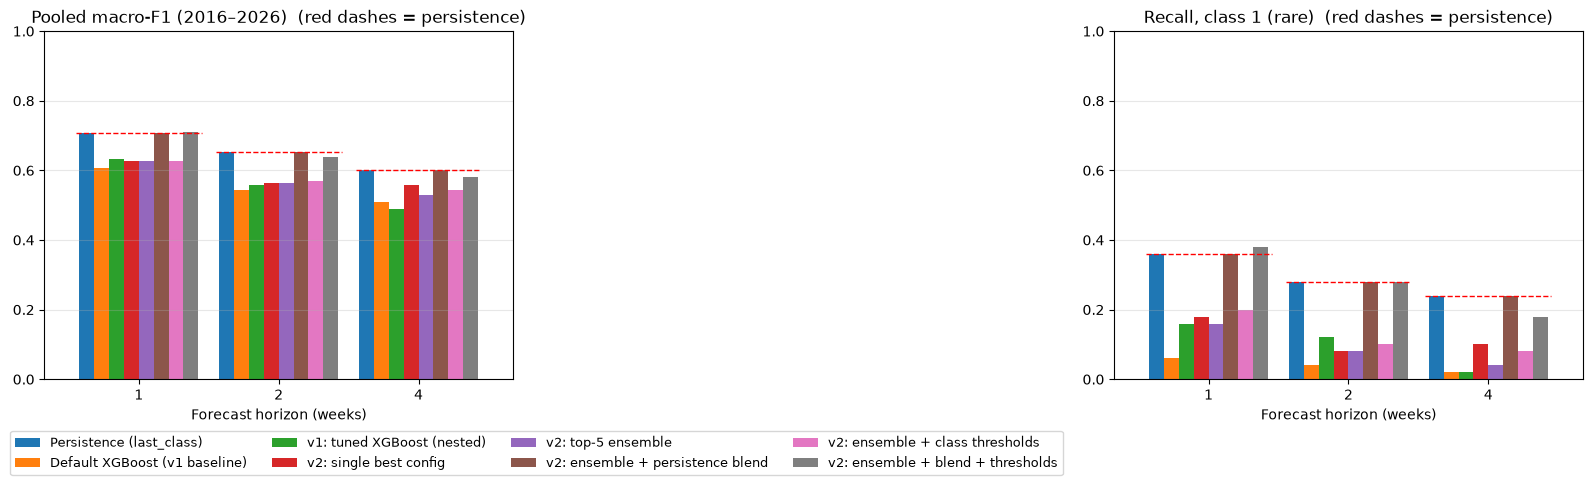

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric, title in zip(axes, ["macro_f1", "recall_c1"],
                             ["Pooled macro-F1 (2016–2026)", "Recall, class 1 (rare)"]):
    pivot = results.pivot(index="horizon", columns="model", values=metric)[MODEL_ORDER]
    pivot.plot(kind="bar", ax=ax, rot=0, width=0.85, legend=False)
    persist = pivot["Persistence (last_class)"]
    for i, v in enumerate(persist):
        ax.hlines(v, i - 0.45, i + 0.45, colors="red", linestyles="--", lw=1)
    ax.set_title(title + "  (red dashes = persistence)")
    ax.set_xlabel("Forecast horizon (weeks)")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(loc="upper center", bbox_to_anchor=(1.05, -0.13), ncol=4, fontsize=9)
plt.tight_layout()
plt.show()

### F. How Sure Are We? Bootstrap Confidence Intervals Against Persistence

Pooled macro-F1 differences between models are small, and the test weeks are few and autocorrelated. Resampling individual weeks would make the intervals look narrower than they really are, so this resamples **whole bloom years** (11 test years) with replacement, 2,000 times. For each model it reports the 95% interval of *(model − persistence)* and the share of resamples in which the model came out ahead (`p_better`) or behind (`p_worse`).

In [17]:
rng = np.random.default_rng(SEED)
N_BOOT = 2000
ci_rows = []
for horizon in HORIZONS:
    hp = all_preds[all_preds["horizon"] == horizon]
    base = hp[hp["model"] == "Persistence (last_class)"].sort_values("row")
    y_true = base["y_true"].to_numpy()
    y_base = base["y_pred"].to_numpy()
    year_arr = base["test_year"].to_numpy()
    years = np.unique(year_arr)
    pos_by_year = {y: np.flatnonzero(year_arr == y) for y in years}
    boot_pos = [np.concatenate([pos_by_year[y] for y in rng.choice(years, len(years))])
                for _ in range(N_BOOT)]
    for m in MODEL_ORDER[1:]:
        if m.startswith("v1: tuned"):
            continue  # v1 predictions are not stored in this notebook
        y_model = (hp[hp["model"] == m].set_index("row")["y_pred"]
                   .reindex(base["row"]).to_numpy())
        diffs = np.array([macro_f1_np(y_true[p], y_model[p]) - macro_f1_np(y_true[p], y_base[p])
                          for p in boot_pos])
        ci_rows.append({"horizon": horizon, "model": m,
                        "diff_vs_persistence": macro_f1_np(y_true, y_model) - macro_f1_np(y_true, y_base),
                        "ci_low": np.percentile(diffs, 2.5), "ci_high": np.percentile(diffs, 97.5),
                        "p_better": (diffs > 0).mean(), "p_worse": (diffs < 0).mean()})
ci_df = pd.DataFrame(ci_rows)
display(ci_df.round(3))

,horizon,model,diff_vs_persistence,ci_low,ci_high,p_better,p_worse
0,1,Default XGBoost (v1 baseline),-0.100,-0.170,-0.024,0.006,0.994
1,1,v2: single best config,-0.081,-0.151,-0.006,0.016,0.984
2,1,v2: top-5 ensemble,-0.081,-0.141,-0.021,0.004,0.996
3,1,v2: ensemble + persistence blend,0.000,0.000,0.000,0.000,0.000
4,1,v2: ensemble + class thresholds,-0.081,-0.145,-0.021,0.004,0.996
5,1,v2: ensemble + blend + thresholds,0.002,-0.011,0.014,0.554,0.439
6,2,Default XGBoost (v1 baseline),-0.107,-0.242,0.003,0.036,0.964
7,2,v2: single best config,-0.087,-0.138,-0.022,0.000,1.000
8,2,v2: top-5 ensemble,-0.087,-0.140,-0.020,0.002,0.998
9,2,v2: ensemble + persistence blend,0.000,0.000,0.000,0.000,0.000


### Performance by Test Year and Confusion Matrices

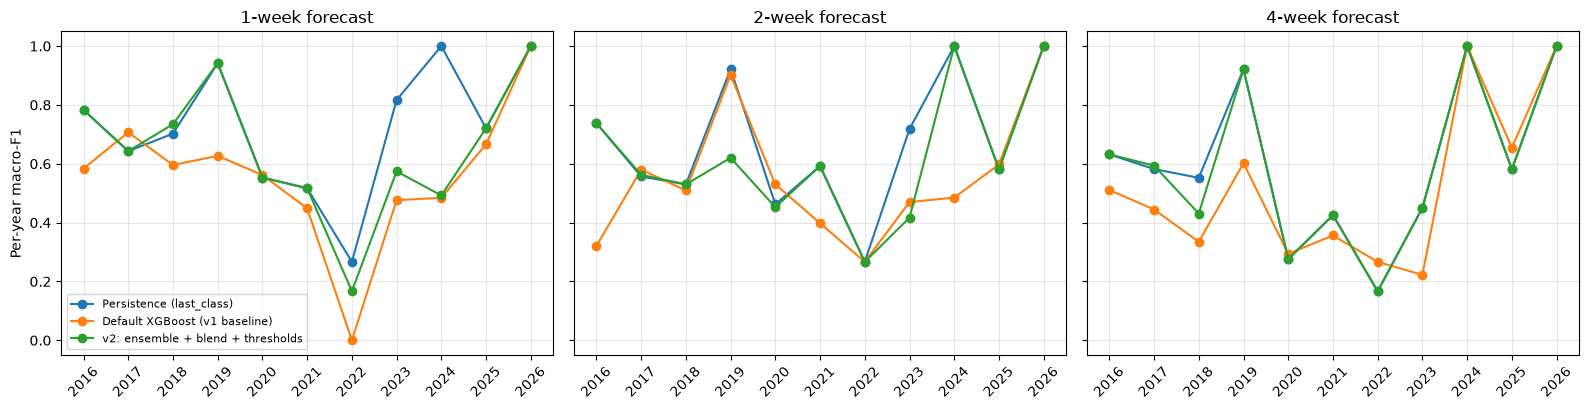

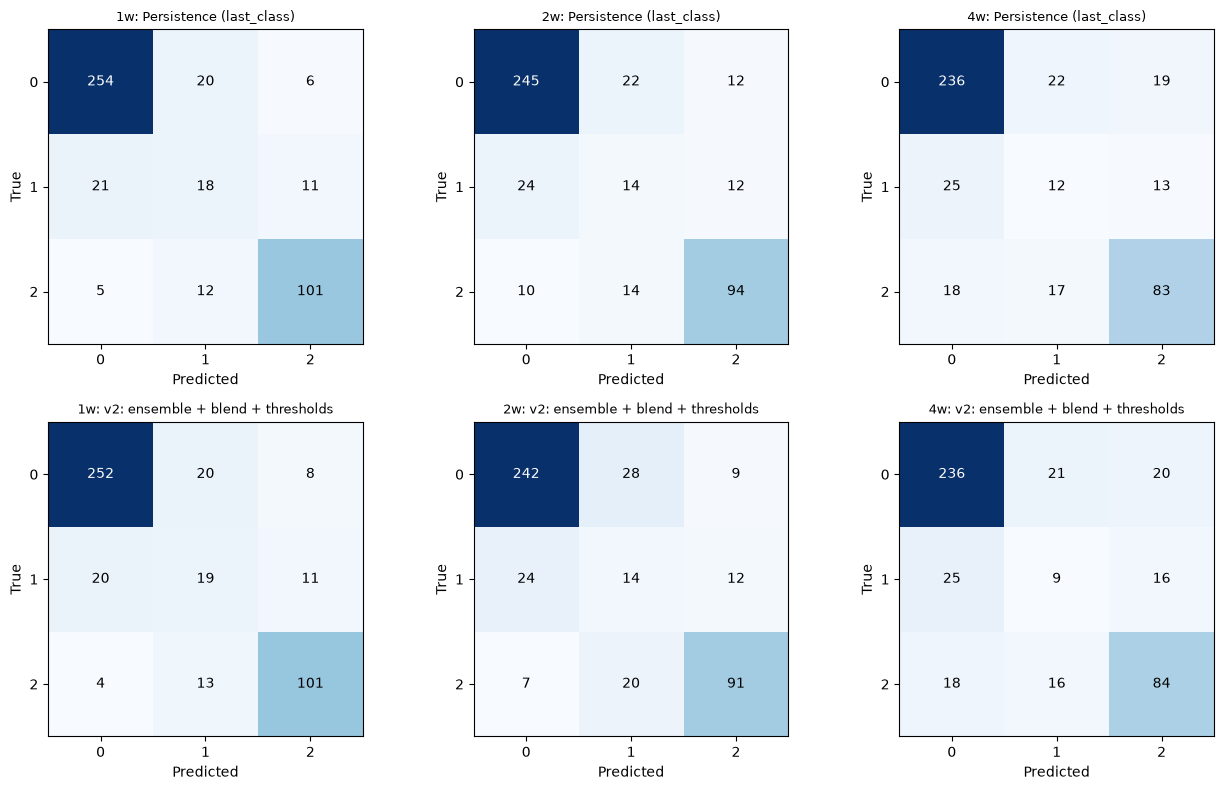

In [18]:
FINAL = "v2: ensemble + blend + thresholds"
plot_models = ["Persistence (last_class)", "Default XGBoost (v1 baseline)", FINAL]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, horizon in zip(axes, HORIZONS):
    for m in plot_models:
        g = all_preds[(all_preds["horizon"] == horizon) & (all_preds["model"] == m)]
        per_year = g.groupby("test_year").apply(
            lambda d: f1_score(d["y_true"], d["y_pred"], average="macro", zero_division=0),
            include_groups=False)
        ax.plot(per_year.index, per_year.values, marker="o", label=m)
    ax.set_title(f"{horizon}-week forecast")
    ax.set_xticks(TEST_YEARS)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Per-year macro-F1")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for col, horizon in enumerate(HORIZONS):
    for row, m in enumerate(["Persistence (last_class)", FINAL]):
        g = all_preds[(all_preds["horizon"] == horizon) & (all_preds["model"] == m)]
        cm = confusion_matrix(g["y_true"], g["y_pred"], labels=CLASSES)
        ax = axes[row, col]
        ax.imshow(cm, cmap="Blues")
        for i in range(3):
            for j in range(3):
                ax.text(j, i, cm[i, j], ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xticks(CLASSES)
        ax.set_yticks(CLASSES)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
        ax.set_title(f"{horizon}w: {m}", fontsize=9)
plt.tight_layout()
plt.show()

### Final Per-Horizon Models

For deployment, the full pipeline is rerun using **all** folds through 2026 to choose the 5 configurations and (α, w₁, w₂). Each of the 5 is then refit on every labelled week. The saved bundle holds the 5 models, their feature lists and the post-processing settings. Quote the nested scores above, not anything computed here, as the expected performance.

In [19]:
final_bundles = {}
for horizon in HORIZONS:
    A = arrays[horizon]
    all_mask = np.ones(len(A["y"]), dtype=bool)
    _, top, (alpha, w1, w2), score_all = run_pipeline(
        A, all_mask, K_ENSEMBLE, VARIANTS[FINAL]["grid"])
    data, target = horizon_data(horizon)
    members = []
    for c in top:
        cfg = next(x for x in CONFIGS if x["config_id"] == A["config_ids"][c])
        feats = FEATURE_SETS[cfg["feature_set"]]
        model = XGBClassifier(**BASE_PARAMS, **cfg["params"])
        model.fit(data[feats], data[target],
                  sample_weight=sample_weights(data[target], cfg["weighting"]))
        members.append({"config_id": cfg["config_id"], "feature_set": cfg["feature_set"],
                        "features": feats, "params": {**BASE_PARAMS, **cfg["params"]},
                        "model": model})
    final_bundles[horizon] = {"members": members, "alpha": alpha,
                              "class_multipliers": [1.0, w1, w2]}
    print(f"{horizon}-week: alpha = {alpha}, multipliers = (1, {w1}, {w2}) | members: "
          + ", ".join(m["config_id"] for m in members))


def predict_bundle(bundle, df, return_proba=False):
    """Ensemble-average probabilities, blend with persistence, apply class multipliers."""
    P = np.mean([m["model"].predict_proba(df[m["features"]]) for m in bundle["members"]], axis=0)
    Q = (1 - bundle["alpha"]) * P + bundle["alpha"] * np.eye(3)[df["last_class"].astype(int)]
    Q = Q * np.array(bundle["class_multipliers"])
    return Q if return_proba else Q.argmax(1)

1-week: alpha = 0.5, multipliers = (1, 1.0, 1.0) | members: kb_only|hp1, kb_only|hp11, kb_only|hp4, kb_only|hp3, kb_only|hp7


2-week: alpha = 0.5, multipliers = (1, 1.5, 1.0) | members: kb_physical_lags|hp2, kb_physical_lags|hp0, kb_physical_lags|hp3, kb_physical_lags|hp12, kb_physical_lags|hp5


4-week: alpha = 0.5, multipliers = (1, 1.5, 1.0) | members: kb_nutrients|hp0, kb_nutrients|hp1, kb_only|hp2, kb_nutrients|hp11, kb_nutrients|hp8


### Feature Importance of the Final Ensembles

Gain importance averaged over the 5 members, counting a feature as 0 in members that don't use it. Orange bars are lagged environmental features added in v1. Importance shows what the models relied on, not cause and effect.

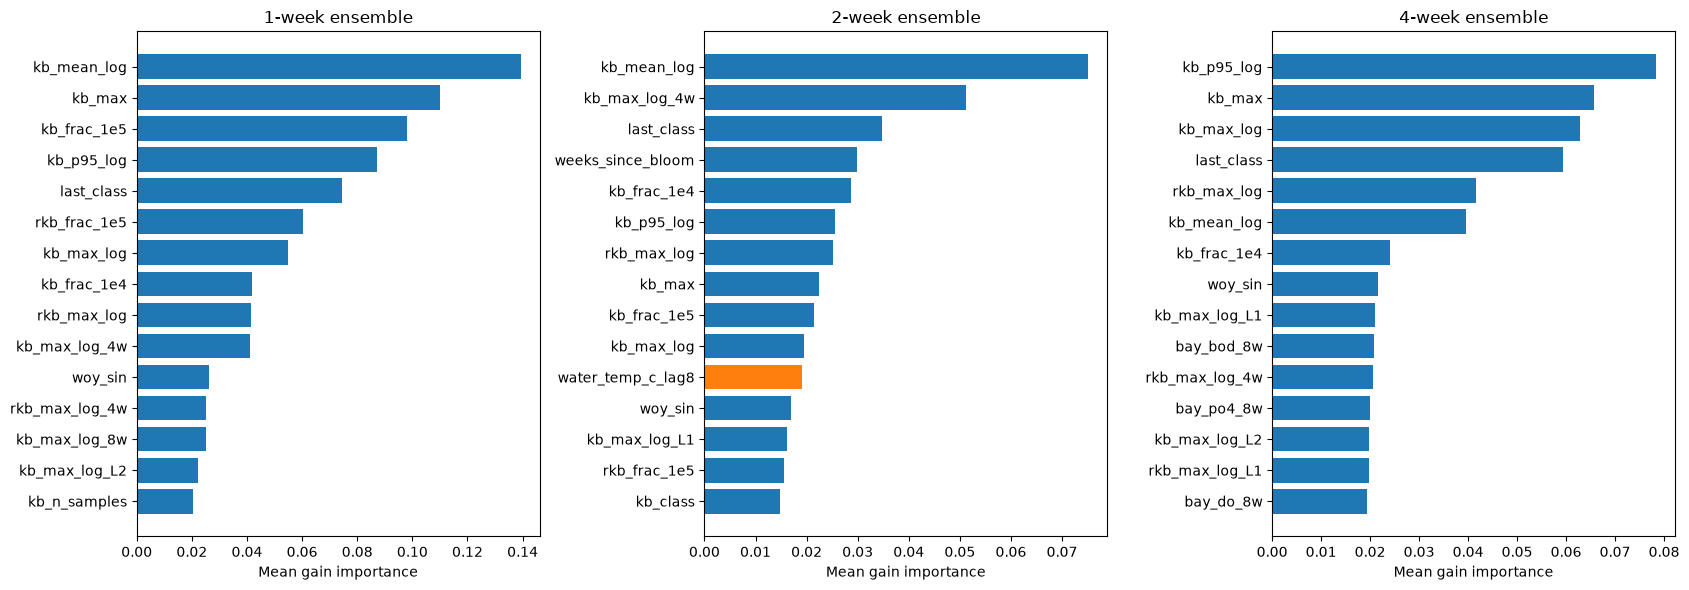

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, horizon in zip(axes, HORIZONS):
    imps = [pd.Series(m["model"].feature_importances_, index=m["features"])
            for m in final_bundles[horizon]["members"]]
    imp = pd.concat(imps, axis=1).fillna(0).mean(axis=1).nlargest(15).sort_values()
    ax.barh(imp.index, imp.values, color=["C1" if f in ENV_LAG_COLS else "C0" for f in imp.index])
    ax.set_title(f"{horizon}-week ensemble")
    ax.set_xlabel("Mean gain importance")
plt.tight_layout()
plt.show()

### Save the Final Models as Pickle Files

Each horizon is saved as one pickle in `results_v2/models/`. It holds the 5 fitted members, their feature lists, α, the class multipliers and reproducibility metadata (seed, training period, library versions and a checksum of the data). A JSON copy of every member is also saved in XGBoost's native format, which loads across library versions. The next cell reloads everything and checks that the predictions are identical.

**Using a saved model:**

```python
import pickle, numpy as np
with open("results_v2/models/xgb_v2_1w.pkl", "rb") as f:
    bundle = pickle.load(f)
P = np.mean([m["model"].predict_proba(new_df[m["features"]]) for m in bundle["members"]], axis=0)
Q = (1 - bundle["alpha"]) * P + bundle["alpha"] * np.eye(3)[new_df["last_class"].astype(int)]
pred = (Q * np.array(bundle["class_multipliers"])).argmax(1)
```

Load a pickle with the same XGBoost version it was saved with (recorded in `bundle["versions"]`), and only unpickle files you created yourself.

In [21]:
import pickle
import platform
import sklearn
import xgboost

MODEL_DIR = os.path.join(RESULTS_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)
with open(DATA_PATH, "rb") as f:
    data_sha256 = hashlib.sha256(f.read()).hexdigest()

for horizon, bundle in final_bundles.items():
    data, target = horizon_data(horizon)
    meta = {
        "horizon_weeks": horizon, "target": target,
        "pipeline": "mean of member probabilities -> blend with one-hot(last_class) by alpha "
                    "-> multiply by class_multipliers -> argmax",
        "k_ensemble": K_ENSEMBLE, "class_weighting": V2_WEIGHTING, "seed": SEED,
        "n_training_rows": int(len(data)),
        "training_period": [str(data["week_ending"].min().date()),
                            str(data["week_ending"].max().date())],
        "env_lag_vars": LAG_VARS, "env_lags": LAGS,
        "data_file": DATA_PATH, "data_sha256": data_sha256,
        "versions": {"xgboost": xgboost.__version__, "scikit-learn": sklearn.__version__,
                     "pandas": pd.__version__, "numpy": np.__version__,
                     "python": platform.python_version()},
    }
    bundle.update(meta)
    with open(os.path.join(MODEL_DIR, f"xgb_v2_{horizon}w.pkl"), "wb") as f:
        pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)

    json_meta = {**meta, "alpha": bundle["alpha"], "class_multipliers": bundle["class_multipliers"],
                 "members": []}
    for i, m in enumerate(bundle["members"]):
        fname = f"xgb_v2_{horizon}w_member{i}.json"
        m["model"].save_model(os.path.join(MODEL_DIR, fname))
        json_meta["members"].append({"file": fname, "config_id": m["config_id"],
                                     "features": m["features"], "params": m["params"]})
    with open(os.path.join(MODEL_DIR, f"xgb_v2_{horizon}w_metadata.json"), "w") as f:
        json.dump(json_meta, f, indent=2)
    print(f"Saved {os.path.join(MODEL_DIR, f'xgb_v2_{horizon}w.pkl')} "
          f"(+ {len(bundle['members'])} JSON members)")

Saved results_v2\models\xgb_v2_1w.pkl (+ 5 JSON members)


Saved results_v2\models\xgb_v2_2w.pkl (+ 5 JSON members)


Saved results_v2\models\xgb_v2_4w.pkl (+ 5 JSON members)


In [22]:
for horizon in HORIZONS:
    with open(os.path.join(MODEL_DIR, f"xgb_v2_{horizon}w.pkl"), "rb") as f:
        loaded = pickle.load(f)
    with open(os.path.join(MODEL_DIR, f"xgb_v2_{horizon}w_metadata.json")) as f:
        jm = json.load(f)
    json_members = []
    for m in jm["members"]:
        mdl = XGBClassifier()
        mdl.load_model(os.path.join(MODEL_DIR, m["file"]))
        json_members.append({"model": mdl, "features": m["features"]})
    from_json = {"members": json_members, "alpha": jm["alpha"],
                 "class_multipliers": jm["class_multipliers"]}

    data, _ = horizon_data(horizon)
    expected = predict_bundle(final_bundles[horizon], data, return_proba=True)
    ok_pkl = np.allclose(predict_bundle(loaded, data, return_proba=True), expected)
    ok_json = np.allclose(predict_bundle(from_json, data, return_proba=True), expected)
    print(f"{horizon}-week: pickle identical = {ok_pkl}, JSON identical = {ok_json}")
    assert ok_pkl and ok_json

1-week: pickle identical = True, JSON identical = True


2-week: pickle identical = True, JSON identical = True


4-week: pickle identical = True, JSON identical = True


## Conclusion

**Pooled macro-F1 on the 2016–2026 test weeks** (all scores honest and nested, except persistence, which needs no tuning):

| Horizon | Persistence | v1 tuned | v2 single best | v2 top-5 ensemble | v2 full pipeline | Full pipeline − persistence (95% CI) |
| --- | --- | --- | --- | --- | --- | --- |
| 1 week | 0.708 | 0.634 | 0.626 | 0.626 | **0.709** | +0.002 (−0.011 to +0.014) |
| 2 weeks | **0.652** | 0.557 | 0.564 | 0.565 | 0.639 | −0.012 (−0.037 to 0.000) |
| 4 weeks | **0.600** | 0.488 | 0.557 | 0.530 | 0.581 | −0.019 (−0.064 to +0.006) |

**1. The full pipeline improves on v1 by +0.08 to +0.09 macro-F1 at every horizon and roughly ties persistence, but does not clearly beat it.** At 1 week it matches persistence (0.709 vs 0.708) and recalls slightly more class-1 weeks (38% vs 36%). The confidence interval is centered on zero, so this is a tie, not a win. At 2 and 4 weeks it is 0.01–0.02 below persistence. Those intervals reach zero, so the gap may be noise, but there is still no evidence of a gain.

**2. Almost all of the gain comes from leaning on persistence.** The nested selection chose α = 0.5 in nearly every year, and at α = 0.5 the forecast *is* persistence unless a class multiplier pushes the model's prediction past it. In practice the final model is **persistence, with occasional XGBoost overrides toward class 1 or class 2** (w₁ = 1.5–2). The overrides gain a little at 1 week and lose a little at 2 and 4 weeks.

**3. The focused search and the ensemble did not help at 1 or 2 weeks.** Without the blend, v2's single best configuration (0.626 / 0.564) is about level with v1 (0.634 / 0.557). The 4-week single pick improved from 0.488 to 0.557, but the top-5 ensemble *lowered* it to 0.530: averaging models picked on noisy earlier years didn't stabilize anything. Neither L1 regularization nor `max_delta_step` changed the picture.

**4. Class thresholds lift rare-class recall only a little.** On top of the ensemble, they raised class-1 recall by 2–4 points with almost no change in macro-F1.

**5. Feature findings repeat v1's.** *K. brevis* history alone is best at 1 week. Physical drivers with environmental lags are best at 2 weeks, with the highest median score of any subset (0.599). Nutrients are best at 4 weeks. Every one of the 2-week ensemble's members uses the lagged environmental features.

**What this means:** with about 600 labelled training weeks and only 60 class-1 weeks, XGBoost cannot learn much beyond "next week looks like this week". **Persistence should be the reference forecast for this dataset**, and any future model should be judged on whether it beats it, with confidence intervals.

**Recommended next steps**
* **Reframe the target as a change:** predict whether next week's class will differ from `last_class` (up or down). That is exactly where persistence fails, and it gives the model a focused, if rare, signal.
* **Get more data:** add neighbouring stations or regions (for example other HABSOS sites along the Gulf coast), or longer histories, so the rare transitions appear more often.
* **Use probabilities, not classes:** report calibrated probabilities of class ≥ 1, scored with Brier score or ROC-AUC. These can show skill that macro-F1 on a 3-class `argmax` hides.

The final per-horizon bundles (5 models + α + class multipliers) are saved in `results_v2/models/` as pickle files, with JSON copies and metadata.

## Resources
1. XGBoost parameters, including `max_delta_step` for imbalanced classes: https://xgboost.readthedocs.io/en/stable/parameter.html
2. scikit-learn, class-balanced sample weights: https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_sample_weight.html
3. Efron & Tibshirani, *An Introduction to the Bootstrap* (1993), on resampling whole groups (cluster bootstrap) when observations are dependent.